In [1]:
# mount google drive
from google.colab import drive 
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# imports block 
import os
from pathlib import Path
from matplotlib import pyplot as plt
import pandas as pd
import re

In [3]:
# Constants block
DATASET_NAME = "filtered_dataset_ferret_3"
CSV_BASE_PATH = Path("/content/drive/MyDrive/Morph_Evaluation")
FMR = 100

# get evaluation csvs for similatiry none sharp+parameters and blur+blur parameters
BASE_NAME=f"{DATASET_NAME}_cosine_similarity"
MASKING_METHODS = ("none", "sharp", "blur")

# list of all csvs for the given dataset 
CSV_FILES = ()

constructed_path = os.path.join(CSV_BASE_PATH, BASE_NAME)

for MASKING_METHOD in MASKING_METHODS: 
    pattern = f"{BASE_NAME}_{MASKING_METHOD}*.csv"
    all_csvs_by_masking_method = tuple(CSV_BASE_PATH.glob(pattern=pattern))
    CSV_FILES += all_csvs_by_masking_method

print(CSV_FILES)

(PosixPath('/content/drive/MyDrive/Morph_Evaluation/filtered_dataset_ferret_3_cosine_similarity_none.csv'), PosixPath('/content/drive/MyDrive/Morph_Evaluation/filtered_dataset_ferret_3_cosine_similarity_sharp_5_9.csv'), PosixPath('/content/drive/MyDrive/Morph_Evaluation/filtered_dataset_ferret_3_cosine_similarity_blur_5_9_5.csv'))


In [4]:
# Functions to compute MMPMR and RIAPAR from evaluation CSV files

def _boolean_series(values: pd.Series) -> pd.Series:
    """Convert boolean-like CSV values to True/False and reject other values."""
    normalized = values.astype("string").str.strip().str.lower()
    return normalized.map({"true": True, "false": False}).dropna()


def calculate_mmpmr(
    csv_path: str,
    fooled_column: str = "fooled",
) -> float:
    """Return MMPMR as successful morph attacks divided by valid attempts.

    The ``fooled`` column must contain True/False values. Missing or invalid
    values are excluded from both the numerator and denominator.
    """
    csv_data = pd.read_csv(csv_path, header=0)
    print(f"Headers: {list(csv_data.columns)}")

    if fooled_column not in csv_data.columns:
        raise KeyError(
            f"Column {fooled_column!r} was not found. "
            f"Available columns: {list(csv_data.columns)}"
        )

    fooled = _boolean_series(csv_data[fooled_column])
    if fooled.empty:
        raise ValueError(f"Column {fooled_column!r} contains no valid True/False values")

    mmpmr = float(fooled.mean())
    print(
        f"Loaded {csv_path}: {len(fooled)} valid attempts. "
        f"Successful attacks: {int(fooled.sum())}. "
        f"MMPMR at FMR={FMR}: {mmpmr:.6f} ({mmpmr:.2%})"
    )
    return mmpmr


def calculate_riapar(
    csv_path: str,
    fnmr_column: str = "fnmr",
    fooled_column: str = "fooled",
) -> float:
    """Return RIAPAR(FMR) = FNMR(FMR) + IAPAR(FMR).

    ``fooled`` is used as the per-attempt attack-success indicator, so its
    mean is IAPAR at the selected FMR operating point. The CSV must contain
    either one FNMR value or one FNMR value per valid attempt.
    """
    csv_data = pd.read_csv(csv_path, header=0)
    required_columns = {fooled_column, fnmr_column}
    missing_columns = required_columns.difference(csv_data.columns)
    if missing_columns:
        raise KeyError(
            f"Missing columns: {sorted(missing_columns)}. "
            f"Available columns: {list(csv_data.columns)}"
        )

    fooled = _boolean_series(csv_data[fooled_column])
    fnmr = pd.to_numeric(csv_data[fnmr_column], errors="coerce")
    valid = fooled.index.intersection(fnmr.dropna().index)
    if valid.empty:
        raise ValueError("No rows contain both a valid fooled value and FNMR value")

    iapar = float(fooled.loc[valid].mean())
    fnmr_value = float(fnmr.loc[valid].mean())
    riapar = fnmr_value + iapar
    print(
        f"FMR={FMR}: FNMR={fnmr_value:.6f}, IAPAR={iapar:.6f}, "
        f"RIAPAR={riapar:.6f}"
    )
    return riapar


# Examples:
# mmpmr_fmr = calculate_mmpmr(CSV_FILES[0])
# riapar_fmr = calculate_riapar(CSV_FILES[0], fnmr_column="fnmr")

In [5]:
# create column plots and print calculated metrics for the given dataset and masking methods

finished_metrics = {}

for file in CSV_FILES: 
    # extracting the masking method and parameters from the file name
    file_name = os.path.basename(file)  
    method_and_params = re.search(r"((none)|(sharp)|(blur)).*(?=\.csv)", file_name).group(0)
    print(f"Processing file: {file_name}")
    mmpmr_fmr = calculate_mmpmr(file)
    finished_metrics[method_and_params] = {"mmpmr_fmr": mmpmr_fmr}
    # riapar_fmr = calculate_riapar(file, fnmr_column="fnmr") we are testing only on morphs for now so no riapar applicable as no bona fide attempts are present.
    # fnmr is also going to wait as it requires bona fide attemps to be present or just use the model on a bona fide dataset and then just add it to the csv before.

Processing file: filtered_dataset_ferret_3_cosine_similarity_none.csv
Headers: ['morph', 'verification1', 'verification2', '1_similarity', '2_similarity', 'fooled']
Loaded /content/drive/MyDrive/Morph_Evaluation/filtered_dataset_ferret_3_cosine_similarity_none.csv: 46 valid attempts. Successful attacks: 44. MMPMR at FMR=100: 0.956522 (95.65%)
Processing file: filtered_dataset_ferret_3_cosine_similarity_sharp_5_9.csv
Headers: ['morph', 'verification1', 'verification2', '1_similarity', '2_similarity', 'fooled']
Loaded /content/drive/MyDrive/Morph_Evaluation/filtered_dataset_ferret_3_cosine_similarity_sharp_5_9.csv: 46 valid attempts. Successful attacks: 38. MMPMR at FMR=100: 0.826087 (82.61%)
Processing file: filtered_dataset_ferret_3_cosine_similarity_blur_5_9_5.csv
Headers: ['morph', 'verification1', 'verification2', '1_similarity', '2_similarity', 'fooled']
Loaded /content/drive/MyDrive/Morph_Evaluation/filtered_dataset_ferret_3_cosine_similarity_blur_5_9_5.csv: 46 valid attempts. Suc

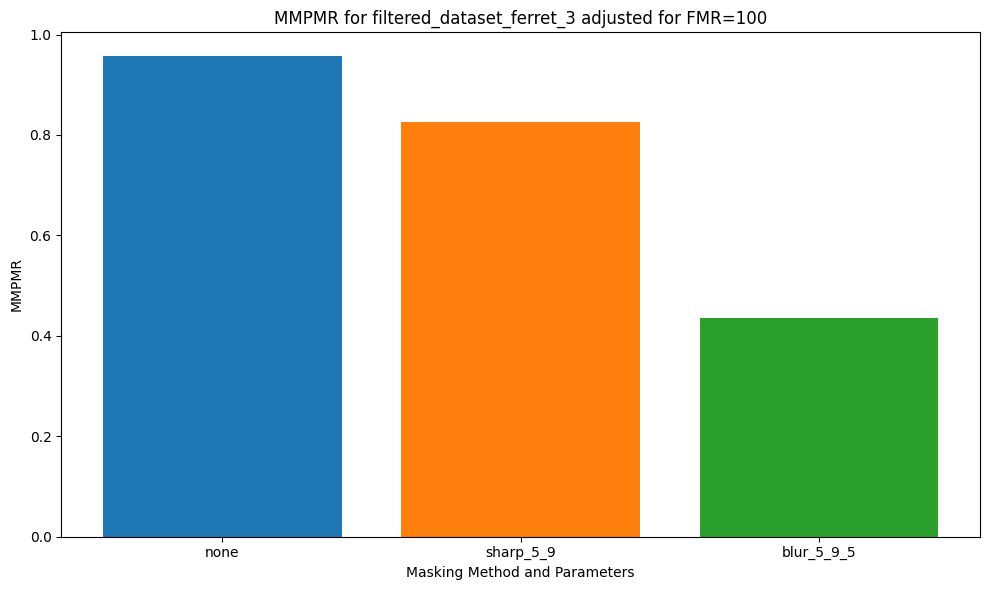

In [6]:
# create column plot for the mmpmr
fig, ax = plt.subplots(figsize=(10, 6), dpi=100, nrows = 1, ncols = 1)
ax.set_title(f"MMPMR for {DATASET_NAME} adjusted for FMR={FMR}")
for method_and_params, metrics in finished_metrics.items():
    ax.bar(method_and_params, metrics["mmpmr_fmr"], label=method_and_params)
ax.set_xlabel("Masking Method and Parameters")
ax.set_ylabel("MMPMR")
plt.tight_layout()
plt.show()